# Wi-Fi CSI presence detection: complete code (Stage 1 + Stage 2)

Room 4 of the IEEE DataPort *CSI Dataset for WiFi Based Human Detection* (DOI 10.21227/smn7-jb67): empty room (label 0) vs one person present (label 1).

1. **Setup**: imports, seeds, constants, data location, helper functions
2. **Stage 1 - data analysis**: inspection, feature selection checks, statistics, split, figures
3. **Stage 2 - logistic regression**: three feature sets (LR_IQR, LR_MEDIAN, LR_CHANGE)
4. **Stage 2 - convolutional neural network** (CNN)
5. **Model comparison, final choice and test error**

# Background Information - What is WiFi and how does it work?

Every radio signal is fundamentally an electromagnetic wave travelling through the air oscillating at some frequency. Different technologies get assigned different frequency ranges (mostly by international agreement) and WiFi signals are mainly around 2.4GHz. WiFi is a protocol that allows devices to wirelessly exchange data with each other. The protocol in short:
* A subcarrier is a radio wave at one specific frequency. 
* Your data starts as bits inside your phone. These bits then get grouped into small chunks (allows better information encoding) and then split across subcarriers.
* Each subcarrier gets its own ongoing stream of these chunks which are then used to transform the subcarriers amplitude and phase (based on a lookup table).
* These subcarriers then travel through the air or through walls, picking up some real-world distortion.
* The router then measures each subcarrier's actual amplitude/phase (its CSI) and decodes the information turning everything back into the original data.
* This whole technique is called Orthogonal Frequency-Divison Multplexing (OFDM). The transmission of a group of data is also called a **packet**.

Channel State Information (CSI) is data that WiFi hardware (like a router) computes as a part of its normal operations. It describes how the radio signal was distorted travelling from a transmitter to a receiver (i.e., did the signal get weaker or did its phase shift). The frequency range in which the subcarriers operate in is called a channel. So around 2.4GHz there are multiple channels which usually have a range of 20MHz. The main benefit for having multiple channels is so that your network has its own frequency space. If your neighbor is using channel 6, your WiFi would use channel 11 so that there is no interference.

## The Aim of the Report

With an understanding of how WiFi works, the aim of this report can be better understood. Research shows that when a person walks through a room their body can absorb/reflect WiFi signals which can affect CSI in a detectable way. The goal of this report is to predict human presence based on these distortions.

## 1. Setup
- **JupyterHub:** upload `data_room4.zip` (plus the optional `data_room4_phase.zip` and `data_lab_static.zip`) next to this notebook; the cell below unzips them once. PyTorch is needed for Section 4.
- **Local repo:** uses the project's `CSV Files/` folder one level up.

In [1]:
import glob
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.utils.class_weight import compute_sample_weight
import warnings

# numpy 2.0 + macOS Accelerate raises spurious "encountered in matmul" warnings (results are unaffected)
warnings.filterwarnings("ignore", message=".*encountered in matmul")

# fixed seeds so every run gives the same weights, batch order and results
torch.manual_seed(0)
np.random.seed(0)

# constants (same values as notebooks/constants.py)
N_PHASE_FILES = 10   # first 10 recordings per class are enough to show the pattern
EXPECTED_FILES = {"empty": 10, "person": 85, "lab_static": 91}  # how many files should be in each folder
DROP_SUBCARRIERS = [0, 48]   # band edges (noisy, so drop), see "edge-subcarriers" below
FILE_S = 70    # seconds between consecutive file start times (from the filenames)
WIN_S = 2      # window length in seconds
FIG_DIR = "figures"
LABELS = {"empty": 0, "person": 1}


# look for the dataset in the current working directory: 
for zip_path in sorted(glob.glob("data_*.zip")): #looks in current folder for zip files with names like data_room4.zip
    with zipfile.ZipFile(zip_path) as z:
        if not os.path.exists(z.namelist()[-1]):     # check if that file has been extracted
            z.extractall(".")  #unzip any data_*.zip in the same folder where .ipynb file lives (JupyterHub)
DATA = "CSV Files" if os.path.isdir("CSV Files") else "../CSV Files" #does a folder name CSV file exist, if yes name it CSV Files
assert os.path.isdir(DATA), "CSV Files/ not found - upload data_room4.zip next to this notebook"


# make the paths easy names
FOLDERS = {
    "empty":      f"{DATA}/room4_iqbal/Static_noperson_channel_11_20mhz/csi_magnitude_data",
    "person":     f"{DATA}/room4_iqbal/Dynamic_1_person_ch11_20mhz/csi_magnitude_data",
    # not used for training: only checked to decide what "Static" means
    "lab_static": f"{DATA}/LAB_Final Year Project/Static_Lab_ch6_20mhz/csi_magnitude_data",
}
# complex (amplitude + phase) files: only read in the phase check below, never used as features
COMPLEX_FOLDERS = {name: FOLDERS[name].replace("csi_magnitude_data", "csi_complex_data")
                   for name in ("empty", "person")} #compact way to make the path names same as above with csi_comple_data instead of csi_magnitude_data

os.makedirs(FIG_DIR, exist_ok=True)

## Helpers
This section loads the data and defines helpers for preprocessing.
1. First find & load the CSVs (list_csv, load_raw, load, load_complex)
2. Summarize signal behaviour per file (iqr, spread, summarise_folder
3. Chop recordings into fixed length windows for individual training examples
4. Organize metadata (timestamps and split data by files)

In [2]:
def list_csv(folder): #given a folder find every.csv file and return the file paths as a sorted list
    return sorted(glob.glob(folder + "/*.csv"))


def load_raw(path): #makes a dataframe out of all the files
    return pd.read_csv(path, header=None)    # no header row: the first line is data; all 49 subcarriers


def load(path): #preprocessing - drop subcarriers 0 and 48 to reduce noise
    return load_raw(path).drop(columns=DROP_SUBCARRIERS)  


def load_complex(path): 
    """Complex CSI from a csi_complex_data file; values are written like '284+410i'.
    thus it requires to convert each string to an actual python complex number, but it requires j instead of i"""
    text = pd.read_csv(path, header=None, dtype=str)
    return text.apply(lambda col: col.str.replace("i", "j").map(complex)).to_numpy()


def iqr(df): #describes the range the middle 50% of datapoints span
    return df.quantile(0.75) - df.quantile(0.25)   # one number per subcarrier


def spread(df):
    """Takes the median of the 47 IQR values - "how variable is this files signal" """
    return iqr(df).median()


def window(df, start_s, length_s=WIN_S, file_s=FILE_S):
    """Cut a length_s-second window starting at start_s, using this file's own packet rate."""
    rate = len(df) / file_s              # estimated packets per second for this file, ex: 500 packets / 70 seconds
    a = int(start_s * rate)              #row index corresponds to 10 sec mark
    b = a + int(length_s * rate)         #row index corresponds to 12 sec mark
    return df.iloc[a:b].to_numpy()           # shape: (packets, 47)


def summarise_folder(files):
    """Load each file ONCE and return its packet count and spread."""
    packets, spreads = [], []
    for f in files:
        df = load(f)
        packets.append(len(df))
        spreads.append(spread(df))
    return packets, spreads


def start_time(path):
    """Recording start time from a filename like csi_20241204_020632_magnitude.csv."""
    stamp = os.path.basename(path).split("_")[1:3]            # ['20241204', '020632']
    return pd.to_datetime("_".join(stamp), format="%Y%m%d_%H%M%S")

#split data into train/validation/test. Done by file now by row - avoids data leakage. so many files go into each 
def split_files(files, n_train, n_val):
    return {"train": files[:n_train],
            "val":   files[n_train:n_train + n_val],
            "test":  files[n_train + n_val:]}

## 2. Stage 1 - data analysis

### Inspect one file per class
Data validation before computing anything.
1. Find all the CSVs for each category
2. Confirm all files have been unzipped correctly
3. Load one representative file from "empty" and "person"
4. Visually confirm: correct shpae, no missing values, and some early on stats

In [3]:
#list_csv is being called on each folder and returning the sorted list of csv files found in it
files = {name: list_csv(folder) for name, folder in FOLDERS.items()} #.items gives you each key value pair, for name, folder unpacks  those values into variables name and folder
print({name: len(f) for name, f in files.items()}) #num of files in each

# Makes sure you have all the files: a half-finished unzip leaves too few files; if this fails, delete "CSV Files/" and re-run from the top
for name, n in EXPECTED_FILES.items():
    assert len(files[name]) in (n, 0 if name == "lab_static" else n), (name, len(files[name]))
#first of file in each folder - this is cleaned data
first = {name: load(files[name][0]) for name in ("empty", "person")}

#Print diagnostic for each sample file
for name, df in first.items():
    print(f"\n=== {name}: {len(files[name])} files, first = {os.path.basename(files[name][0])}") #header: folder name, total files, and file being inspected
    print("shape (packets, subcarriers):", df.shape)
    print("missing values:", df.isna().sum().sum())
    display(pd.DataFrame({"std": df.std(), "IQR": iqr(df)}).T.round(1))

{'empty': 10, 'person': 85, 'lab_static': 91}

=== empty: 10 files, first = csi_20241204_020632_magnitude.csv
shape (packets, subcarriers): (5405, 47)
missing values: 0


,1,2,3,4,5,6,7,8,9,10,...,38,39,40,41,42,43,44,45,46,47
std,255.6,279.0,193.9,266.0,281.0,210.6,293.1,267.0,282.1,183.2,...,14.0,19.4,18.1,18.6,53.1,17.4,18.0,15.8,12.0,15.1
IQR,9.5,9.9,10.2,10.0,8.5,9.2,9.2,9.8,11.5,10.2,...,10.1,10.5,8.8,8.5,7.5,6.7,6.7,6.6,6.2,7.5



=== person: 85 files, first = csi_20241203_223721_magnitude.csv
shape (packets, subcarriers): (10408, 47)
missing values: 0


,1,2,3,4,5,6,7,8,9,10,...,38,39,40,41,42,43,44,45,46,47
std,142.0,127.9,117.9,115.0,113.5,150.0,181.6,217.1,252.0,277.0,...,203.2,225.2,232.9,237.2,227.0,194.8,170.7,144.0,113.9,87.2
IQR,220.7,172.3,138.6,115.4,119.6,226.3,298.8,381.5,455.9,507.4,...,330.8,385.8,417.7,429.2,412.1,341.1,277.5,223.2,160.0,98.0


### Subcarrier comparison - Person vs Empty
An exploratory plot used to compare the wave form of single subcarrier from a room with a person vs. a room without a person.

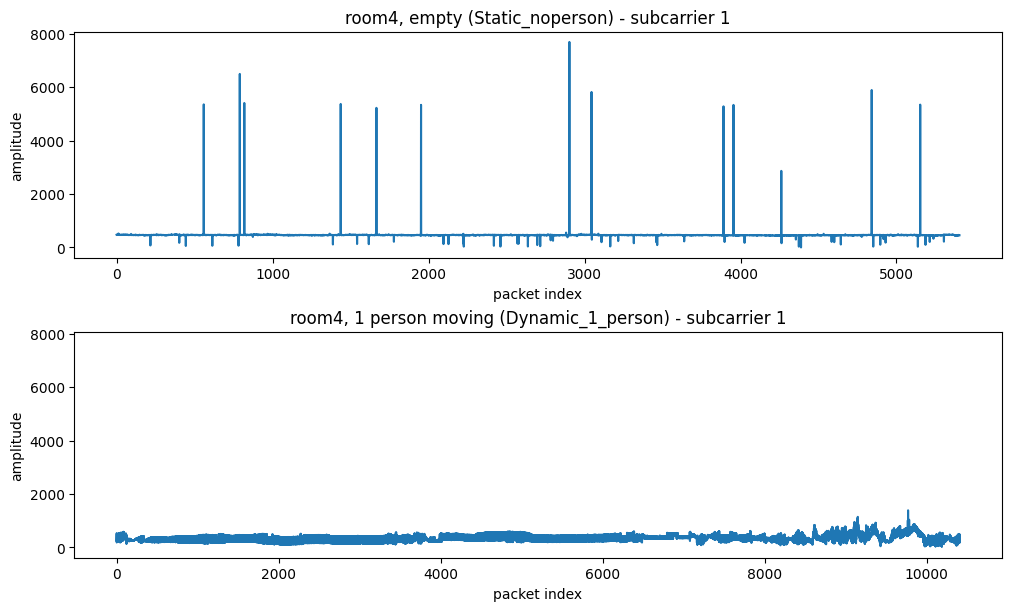

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True, constrained_layout=True)
for ax, name, title in zip(axes, ("empty", "person"),
                           ("room4, empty (Static_noperson)", "room4, 1 person moving (Dynamic_1_person)")):
    ax.plot(first[name][1])
    ax.set_title(f"{title} - subcarrier 1")
    ax.set_xlabel("packet index")
    ax.set_ylabel("amplitude")
plt.savefig(f"{FIG_DIR}/fig_raw_subcarrier1.png", dpi=150)
plt.show()

### Justifying dropping the edge-subcarriers
Checks across every file in "empty" and "person" folders whether subcarriers 0 and 48 are consistently noisier (higher IQR) than a typical subcarrier. edge_table is a summary table justifying the decision

In [5]:
#measuring across every file is subcarrier 0 or 48 consistently more variable than a typical subcarrier in the same file
ratio_rows = []
for name in ("empty", "person"):
    ratios = []
    for f in files[name]:
        r = iqr(load_raw(f))
        inner = r.drop(index=DROP_SUBCARRIERS).median()
        ratios.append((r[0] / inner, r[48] / inner))
    ratios = np.array(ratios)
    for i, sc in enumerate(DROP_SUBCARRIERS):
        ratio_rows.append({"class": name, "subcarrier": sc, "files": len(ratios),
                           "files with ratio > 1": int((ratios[:, i] > 1).sum()),
                           "median ratio": np.median(ratios[:, i]),
                           "min": ratios[:, i].min(), "max": ratios[:, i].max()})
edge_table = pd.DataFrame(ratio_rows).round(2)
edge_table.to_csv(f"{FIG_DIR}/table_edge_subcarriers.csv", index=False)
edge_table

,class,subcarrier,files,files with ratio > 1,median ratio,min,max
0,empty,0,10,10,2.29,1.31,3.13
1,empty,48,10,10,5.26,2.62,6.98
2,person,0,85,27,0.91,0.35,1.86
3,person,48,85,30,0.74,0.14,2.44


### Feature selection: why phase is not used
This checks whether CSI phase carries usable information or is it just hardware noise. Raw CSI phase from commodity Wi-Fi cards are known to carry random per-packet offsets. For the first 10 recordings of each class ("empty" and "person") using subcarriers 1-47, we compute three diagnostics per file and summarize them into one row per class.
1. Circular variance of the phase over time (0 = constant phase, 1 = uniformly random)
2. the median phase jump between consecutive packets (uniformly random phase gives pi/2 = 1.57 rad)
3. And for comparison, the relative spread of the magnitude (IQR / median).

In [6]:
phase_rows = []
for name, folder in COMPLEX_FOLDERS.items():
    complex_files = list_csv(folder)[:N_PHASE_FILES]
    if not complex_files:
        print(f"{name}: no complex files found - upload data_room4_phase.zip to run this check")
        continue
    circ_var, jump, mag_rel = [], [], []
    for f in complex_files:
        c = load_complex(f)[:, 1:48]                    # inner subcarriers, same as the features
        phase, mag = np.angle(c), np.abs(c)
        circ_var.append(np.median(1 - np.abs(np.mean(np.exp(1j * phase), axis=0))))
        jump.append(np.median(np.abs(np.angle(np.exp(1j * np.diff(phase, axis=0))))))
        q75, q25 = np.percentile(mag, [75, 25], axis=0)
        mag_rel.append(np.median((q75 - q25) / np.median(mag, axis=0)))
    phase_rows.append({"class": name, "files": len(complex_files),
                       "phase circular variance": np.median(circ_var),
                       "median phase jump (rad)": np.median(jump),
                       "magnitude IQR / median": np.median(mag_rel)})
phase_table = pd.DataFrame(phase_rows).round(3)
phase_table.to_csv(f"{FIG_DIR}/table_phase_check.csv", index=False)
phase_table

,class,files,phase circular variance,median phase jump (rad),magnitude IQR / median
0,empty,10,0.990,1.572,0.018
1,person,10,0.991,1.575,0.614


### Full-dataset spread summary and 'lab_static' label check
Here every file is loaded and as well as compute the spread. Includes a summary for each class. The code also investigates if 'lab_static' can be trusted

In [7]:
summary = {name: summarise_folder(files[name]) for name in FOLDERS if files[name]}

for name, (packets, spreads) in summary.items():
    print(f"{name:10s} files={len(spreads):3d}  median IQR min={min(spreads):6.1f}  max={max(spreads):6.1f}")

# label check: if the Lab "Static" folder was loaded, compare its spread with room4
if "lab_static" in summary:
    lab = summary["lab_static"][1]
    print(f"\nLab 'Static' range {min(lab):.1f}-{max(lab):.1f} vs room4 empty max {max(summary['empty'][1]):.1f}, "
          f"person min {min(summary['person'][1]):.1f} -> inside the person range, so 'Static' is ambiguous "
          f"(empty in a noisier room, or a still person) and the Lab folders are excluded")

empty      files= 10  median IQR min=   7.7  max=  25.4
person     files= 85  median IQR min=  67.8  max= 303.3
lab_static files= 91  median IQR min= 204.6  max= 275.8

Lab 'Static' range 204.6-275.8 vs room4 empty max 25.4, person min 67.8 -> inside the person range, so 'Static' is ambiguous (empty in a noisier room, or a still person) and the Lab folders are excluded


### Dataset statistics for room 4
This summary table combines: file counts, packet counts, duration, how many training samples after windowing, and repeat of earlier spreads for comparing "empty" vs "person" classes.

In [8]:
rows = []
for name, label in (("empty", 0), ("person", 1)):
    packets, spreads = summary[name]
    rows.append({
        "class": name,
        "label": label,
        "files": len(packets),
        "packets (total)": sum(packets),
        "duration (s, approx.)": len(packets) * FILE_S,
        "packets/s (median)": round(np.median(packets) / FILE_S),
        f"{WIN_S}-s windows (non-overlapping)": len(packets) * (FILE_S // WIN_S),
        "median IQR (min-max)": f"{min(spreads):.1f}-{max(spreads):.1f}",
    })
table = pd.DataFrame(rows)
table.to_csv(f"{FIG_DIR}/table_dataset_stats.csv", index=False)
table

,class,label,files,packets (total),"duration (s, approx.)",packets/s (median),2-s windows (non-overlapping),median IQR (min-max)
0,empty,0,10,57641,700,78,350,7.7-25.4
1,person,1,85,518122,5950,77,2975,67.8-303.3


### Train / validation / test split and data leakage check
Splits each class's files into train/val/test sets using fixed counts. The splitting is done by whole files so a single recording never gets divided across sets.

In [9]:
splits = {
    "empty":  split_files(files["empty"],  n_train=6,  n_val=2),    # 6 / 2 / 2
    "person": split_files(files["person"], n_train=51, n_val=17),   # 51 / 17 / 17
}

split_rows = []
for name, parts in splits.items():
    for part, part_files in parts.items():
        split_rows.append({
            "class": name,
            "set": part,
            "files": len(part_files),
            f"{WIN_S}-s windows": len(part_files) * (FILE_S // WIN_S),
            "first start": start_time(part_files[0]),
            "last start": start_time(part_files[-1]),
        })
split_table = pd.DataFrame(split_rows)
split_table.to_csv(f"{FIG_DIR}/table_split.csv", index=False)

# no file may appear in two sets
all_split = [f for parts in splits.values() for part_files in parts.values() for f in part_files]
assert len(all_split) == len(set(all_split)) == len(files["empty"]) + len(files["person"])
split_table

,class,set,files,2-s windows,first start,last start
0,empty,train,6,210,2024-12-04 02:06:32,2024-12-04 02:12:23
1,empty,val,2,70,2024-12-04 02:13:33,2024-12-04 02:14:43
2,empty,test,2,70,2024-12-04 02:15:53,2024-12-04 02:17:04
3,person,train,51,1785,2024-12-03 22:37:21,2024-12-03 23:35:46
4,person,val,17,595,2024-12-03 23:36:56,2024-12-03 23:55:37
5,person,test,17,595,2024-12-03 23:56:47,2024-12-04 00:15:29


### Figure (a): one 2-s window per class
Here we try to visualize a single 2-second window from the empty and person sample files as side-by-side heatmaps. The color of each square is how strong the signal is at that subcarrier.

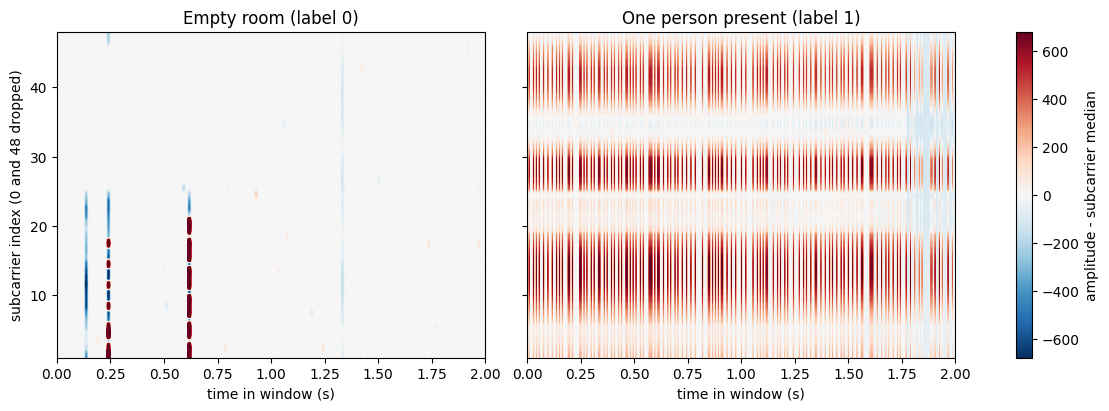

In [10]:
centred = {}
for name in ("empty", "person"):
    w = window(first[name], start_s=10)
    centred[name] = w - np.median(w, axis=0)     # different subcarries sit at differnt amplitude levels so by subtracting median every subcarriers level is 0
lim = np.percentile(np.abs(np.vstack(list(centred.values()))), 99)   # shared colour range, ignores spikes

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, name, title in zip(axes, ("empty", "person"),
                           ("Empty room (label 0)", "One person present (label 1)")):
    c = centred[name]
    im = ax.imshow(c.T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[0, WIN_S, 1, 48])
    ax.set_title(title)
    ax.set_xlabel("time in window (s)")
axes[0].set_ylabel("subcarrier index (0 and 48 dropped)")
fig.colorbar(im, ax=axes, label="amplitude - subcarrier median")
plt.savefig(f"{FIG_DIR}/fig_a_heatmap.png", dpi=150)
plt.show()

### Figure (b): spread per recording, empty vs person

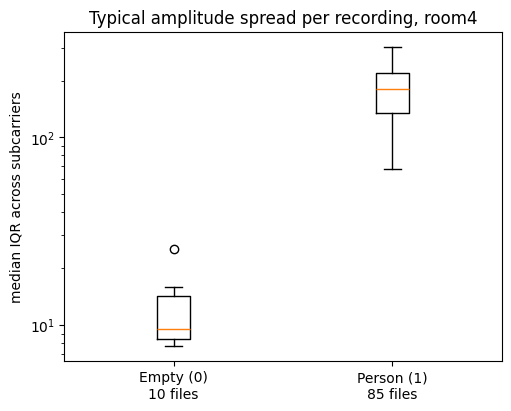

In [11]:
empty_spreads, person_spreads = summary["empty"][1], summary["person"][1]
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
ax.boxplot([empty_spreads, person_spreads])
ax.set_xticks([1, 2], [f"Empty (0)\n{len(empty_spreads)} files", f"Person (1)\n{len(person_spreads)} files"])
ax.set_ylabel("median IQR across subcarriers")
ax.set_yscale("log")          # values span about 7 to 300
ax.set_title("Typical amplitude spread per recording, room4")
plt.savefig(f"{FIG_DIR}/fig_b_spread_boxplot.png", dpi=150)
plt.show()

## 3. Stage 2 - logistic regression
Each 2-second window (about 154 packets x 47 subcarriers) is summarised into per-subcarrier statistics. Three feature sets:
- **LR_IQR**: IQR per subcarrier (47 features)
- **LR_MEDIAN**: IQR + median amplitude per subcarrier (94 features)
- **LR_CHANGE**: IQR + median absolute change between consecutive packets per subcarrier (94 features)

### Features for one window

In [12]:
def window_features(w, kind):
    """Feature vector for one window.

    w:    numpy array of shape (packets, 47), one 2-second window
    kind: "median" -> IQR + median per subcarrier
          "change" -> IQR + median absolute change between consecutive packets
    returns a 1-D array of length 94
    """
    IQR = np.percentile(w, 75, axis=0) - np.percentile(w, 25, axis=0)
    if kind == "median":
       second_array = np.median(w, axis=0)
    elif kind == "change":
       second_array = np.median(np.abs(np.diff(w, axis=0)), axis=0)
    else:
        raise ValueError("Unknown kind")
    return np.concatenate([IQR, second_array], axis=0)

In [13]:
for name in ("empty", "person"):
    w = window(load(files[name][0]), start_s=10)
    for kind in ("median", "change"):
        f = window_features(w, kind)
        print(f"{name:6s} {kind:6s} shape={f.shape}  IQR[:5]={np.round(f[:5], 1)}  {kind}[:5]={np.round(f[47:52], 1)}")

empty  median shape=(94,)  IQR[:5]=[7.8 5.7 6.  5.7 5.9]  median[:5]=[471.2 373.  304.6 293.4 349. ]
empty  change shape=(94,)  IQR[:5]=[7.8 5.7 6.  5.7 5.9]  change[:5]=[4.4 4.2 4.2 4.2 3.9]
person median shape=(94,)  IQR[:5]=[234.2 176.  127.   94.9 103. ]  median[:5]=[231.8 227.4 225.7 228.  229.2]
person change shape=(94,)  IQR[:5]=[234.2 176.  127.   94.9 103. ]  change[:5]=[226.1 166.2 117.4  87.4  92.6]


### X, y for train / validation / test (split by recording, as in Stage 1)

In [14]:
def build_set(part, kind):
    splits = {"empty": split_files(files["empty"], 6, 2),
              "person": split_files(files["person"], 51, 17)}

    X, y = [], []
    for label in ("empty", "person"):
        for path in splits[label][part]:  # each part recording of this class
            df = load(path)
            for start_s in range(0, FILE_S, WIN_S):  # 0, 2, ..., 68 -> 35 windows
                X.append(window_features(window(df, start_s), kind))
                y.append(LABELS[label])
    return np.array(X), np.array(y)

X_train_median, y_train_median = build_set("train", "median")
X_val_median, y_val_median = build_set("val", "median")
X_test_median, y_test_median = build_set("test", "median")

X_train_change, y_train_change = build_set("train", "change")
X_val_change, y_val_change = build_set("val", "change")
X_test_change, y_test_change = build_set("test", "change")

### Standardise with training statistics only

In [15]:
mean_1 = X_train_median.mean(axis=0)
std_1 = X_train_median.std(axis=0)
mean_2 = X_train_change.mean(axis=0)
std_2 = X_train_change.std(axis=0)

X_train_median_standardised = (X_train_median - mean_1) / std_1
X_val_median_standardised = (X_val_median - mean_1) / std_1
X_test_median_standardised = (X_test_median - mean_1) / std_1

X_train_change_standardised = (X_train_change - mean_2) / std_2
X_val_change_standardised = (X_val_change - mean_2) / std_2
X_test_change_standardised = (X_test_change - mean_2) / std_2

### Train logistic regression (class-balanced) and tune C = 1/lambda on validation

In [16]:
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]   # log-spaced candidates


def tune_C(X_train, y_train, X_val, y_val, name):
    """Fit one model per C on the training set, score it on the validation set, return the best C."""
    best_C, best_score = None, -1.0
    for C in C_VALUES:
        logistic_regression = LogisticRegression(C=C, class_weight="balanced", max_iter=1000)
        logistic_regression.fit(X_train, y_train)
        y_pred = logistic_regression.predict(X_val)
        score = balanced_accuracy_score(y_val, y_pred)
        if score > best_score:
            best_C = C
            best_score = score
        print(f"{name:6s}  C={C:<7}  val balanced accuracy={score}")
    print(f"{name:6s}  best C = {best_C}  (val balanced accuracy {best_score})\n")
    return best_C


best_C_median = tune_C(X_train_median_standardised, y_train_median,
                       X_val_median_standardised, y_val_median, "median")
best_C_change = tune_C(X_train_change_standardised, y_train_change,
                       X_val_change_standardised, y_val_change, "change")

median  C=0.001    val balanced accuracy=1.0
median  C=0.01     val balanced accuracy=1.0
median  C=0.1      val balanced accuracy=1.0
median  C=1        val balanced accuracy=1.0
median  C=10       val balanced accuracy=1.0
median  C=100      val balanced accuracy=1.0
median  best C = 0.001  (val balanced accuracy 1.0)

change  C=0.001    val balanced accuracy=0.9991596638655462
change  C=0.01     val balanced accuracy=1.0
change  C=0.1      val balanced accuracy=1.0
change  C=1        val balanced accuracy=1.0
change  C=10       val balanced accuracy=0.9991596638655462
change  C=100      val balanced accuracy=0.9991596638655462
change  best C = 0.01  (val balanced accuracy 1.0)



### Sanity check: shuffled training labels
A model trained on randomly shuffled labels should score about 0.5 (chance); a score near 1.0 would mean leakage.

In [17]:
# If the pipeline is correct, a model trained on randomly shuffled labels can learn nothing real,
# so its validation balanced accuracy should drop to about 0.5 (chance). A score near 1.0 here
# would mean information about the validation labels leaks into training somewhere.

def shuffled_label_check(X_train, y_train, X_val, y_val, C, name, n_runs=5):
    rng = np.random.default_rng(0)
    scores = []
    for _ in range(n_runs):
        y_shuffled = rng.permutation(y_train)            # same class counts, labels no longer match the windows
        logistic_regression = LogisticRegression(C=C, class_weight="balanced", max_iter=1000)
        logistic_regression.fit(X_train, y_shuffled)
        scores.append(balanced_accuracy_score(y_val, logistic_regression.predict(X_val)))
    print(f"{name:6s}  shuffled labels, C={C}: val balanced accuracy "
          f"mean {np.mean(scores):.3f} (runs: {', '.join(f'{s:.3f}' for s in scores)})")


shuffled_label_check(X_train_median_standardised, y_train_median,
                     X_val_median_standardised, y_val_median, best_C_median, "median")
shuffled_label_check(X_train_change_standardised, y_train_change,
                     X_val_change_standardised, y_val_change, best_C_change, "change")

median  shuffled labels, C=0.001: val balanced accuracy mean 0.511 (runs: 0.407, 0.735, 0.260, 0.737, 0.414)
change  shuffled labels, C=0.01: val balanced accuracy mean 0.522 (runs: 0.378, 0.755, 0.313, 0.771, 0.392)


### Weight check: what does each model rely on?
`coef_[0]` holds the weights in feature order: [0:47] = IQR, [47:94] = second statistic.

In [18]:
# coef_[0] holds the 94 weights in feature order: [0:47] = IQR, [47:94] = second statistic.
# The features are standardised, so a larger |weight| means the feature matters more.

def final_model(X_train, y_train, C):
    """Train the model that will be evaluated in the last step (best C, training set only)."""
    logistic_regression = LogisticRegression(C=C, class_weight="balanced", max_iter=1000)
    return logistic_regression.fit(X_train, y_train)


def weight_summary(model, name):
    w = model.coef_[0]
    iqr_importance = np.abs(w[:47]).mean()
    second_importance = np.abs(w[47:]).mean()
    second_sign = np.mean(w[47:])
    print(f"{name:6s}  mean |w| IQR = {iqr_importance}   mean |w| {name} = {second_importance}   "
          f"mean w {name} = {second_sign}")


final_median = final_model(X_train_median_standardised, y_train_median, best_C_median)
final_change = final_model(X_train_change_standardised, y_train_change, best_C_change)
weight_summary(final_median, "median")
weight_summary(final_change, "change")

median  mean |w| IQR = 0.04699069426466203   mean |w| median = 0.045101314632840034   mean w median = 0.0025967166108286236
change  mean |w| IQR = 0.09021371945604177   mean |w| change = 0.07792003359150186   mean w change = 0.07792003359150186


### IQR-only model (LR_IQR)
Both feature sets start with the same 47 IQR columns, so LR_IQR uses the first 47 standardised columns.

In [19]:
# Both feature sets start with the same 47 IQR columns, so the IQR-only features are just the first
# 47 columns; slicing the already-standardised arrays gives the same result as standardising them alone.
X_train_iqr_standardised = X_train_change_standardised[:, :47]
X_val_iqr_standardised   = X_val_change_standardised[:, :47]
X_test_iqr_standardised  = X_test_change_standardised[:, :47]

best_C_iqr = tune_C(X_train_iqr_standardised, y_train_change, X_val_iqr_standardised, y_val_change, "iqr")
final_iqr = final_model(X_train_iqr_standardised, y_train_change, best_C_iqr)

iqr     C=0.001    val balanced accuracy=0.9983193277310924
iqr     C=0.01     val balanced accuracy=1.0
iqr     C=0.1      val balanced accuracy=1.0
iqr     C=1        val balanced accuracy=1.0
iqr     C=10       val balanced accuracy=1.0
iqr     C=100      val balanced accuracy=1.0
iqr     best C = 0.01  (val balanced accuracy 1.0)



### Training and validation errors
Class-weighted logistic loss (the training loss, data term only) and balanced error = 1 - balanced accuracy.

In [20]:
# Two error measures, the same for every set:
#   log loss       = class-weighted logistic loss, the loss the model is trained on (data term only, no regularisation)
#   balanced error = 1 - balanced accuracy, the 0/1 error averaged per class (fair under the 8.5 : 1 imbalance)
# The final method is chosen from the train/val rows; only the chosen model's test row goes into the report as its test error.

def report_errors(model, sets, name):
    """sets: dict like {"train": (X, y), "val": (X, y), "test": (X, y)}, X already standardised."""
    rows = []
    for part, (X, y) in sets.items():
        weights = compute_sample_weight("balanced", y)   # one weight per window: empty ~4.75, person ~0.56
        p = model.predict_proba(X)[:, 1]                 # predicted probability of "person"
        loss = log_loss(y, p, sample_weight=weights)
        b_err = 1 - balanced_accuracy_score(y, model.predict(X))
        print(f"{name:9s} {part:5s}  log loss = {loss:.4f}   balanced error = {b_err:.4f}")
        rows.append({"model": name, "set": part, "logistic loss": loss, "balanced error": b_err})
    print()
    return rows


error_rows = []
error_rows += report_errors(final_median, {"train": (X_train_median_standardised, y_train_median),
                             "val":   (X_val_median_standardised,   y_val_median),}, "LR_MEDIAN")
error_rows += report_errors(final_change, {"train": (X_train_change_standardised, y_train_change),
                             "val":   (X_val_change_standardised,   y_val_change),}, "LR_CHANGE")
error_rows += report_errors(final_iqr,    {"train": (X_train_iqr_standardised,    y_train_change),
                             "val":   (X_val_iqr_standardised,      y_val_change),}, "LR_IQR")

LR_MEDIAN train  log loss = 0.0410   balanced error = 0.0000
LR_MEDIAN val    log loss = 0.0444   balanced error = 0.0000

LR_CHANGE train  log loss = 0.0117   balanced error = 0.0006
LR_CHANGE val    log loss = 0.0151   balanced error = 0.0000

LR_IQR    train  log loss = 0.0196   balanced error = 0.0000
LR_IQR    val    log loss = 0.0256   balanced error = 0.0000



## 4. Stage 2 - convolutional neural network (CNN)

In the previous stage we succesfully inspected the data, checked its quality, and defined the data splits. In the following we will:
* cut every file into 2 second windows to feed into the model
* attach labels to every window (0 or 1)
* Stack them into an array CNN can consume (possibly normalize)
* Define the CNN architecture
* Write the training loop
* Track training vs. validation accuracy/loss per epoch 

### Cut every file into windows.
Each ~70 second file gives about 35 non-overlapping 2-second windows.
Windows can have different row counts because packet rate slightly differs between files, however CNN needs a fixed one. Here we pick the window size to be the smallest window length we can find.

In [21]:
def make_windows(files, label, T): #T is the # of rows every window must have
    X, y = [], [] #X will collect the inputs, y will collect the correct labels
    for f in files:
        df = load(f) #reads on csv file into a table and drops the two edge carriers (helper function)
        for start in range(0, FILE_S, WIN_S):
            w = window(df, start) #cuts out the 2-sec window starting from start
            if len(w) >= T: #safety check
                w = w[:T]
                X.append(w - np.median(w, axis=0)) #computes median for each subcarrier (appending the centered data around 0 to X)
                y.append(label)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32) #turns the arrays into numpy arrays, float32 is the type PyTorch expects (also less memory)

'''Finding T - the smallest window length'''
all_files =files["empty"] + files["person"] #one big list
T = min(len(window(load(f), 10)) for f in all_files) #take a 2sec window starting at 10sec from each file by first loading it, then compare the length of that window (some packet rates are faster than other so more rows), then choose min 

### Next step is to build the splits

In [22]:
def build(part):
    Xe, ye = make_windows(splits["empty"][part],  0, T)
    Xp, yp = make_windows(splits["person"][part], 1, T)
    return np.concatenate([Xe, Xp]), np.concatenate([ye, yp])

X_train, y_train = build("train")
X_val,   y_val   = build("val")
X_test,  y_test  = build("test")

for name, X, y in (("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)):
    print(name, X.shape, y.shape, "empty:", int((y == 0).sum()), "person:", int((y == 1).sum()))
pd.DataFrame(X_train[0][:5,:5])

train (1995, 81, 47) (1995,) empty: 210 person: 1785
val (665, 81, 47) (665,) empty: 70 person: 595
test (665, 81, 47) (665,) empty: 70 person: 595


,0,1,2,3,4
0,2.432702,6.327237,-1.950626,1.491439,-5.763897
1,5.234189,4.724953,2.869820,0.488853,0.587975
2,6.750565,14.484240,7.391074,8.373919,3.815616
3,6.743281,5.205689,9.743284,10.189011,11.285751
4,12.209437,8.930522,11.832970,9.308620,11.742233


### Data validity checks
Before training we check that the data is set up correctly:
* **No leakage:** no recording file appears in more than one split (all overlaps should be empty sets).
* **Class imbalance:** the window counts above show about 8.5 person windows for every empty window, so plain accuracy is misleading (always guessing "person" gives 89.5%).
* **Value level per class:** mean of the median-centred windows per class (empty about 5, person about 21). Sanity check 1 tests whether this alone predicts the label.
* **Packet counts per class:** the ranges overlap between classes, so recording length is not a giveaway.
* **Spread per class:** the standard deviations are similar (about 180 vs 152), so overall spread is not an obvious shortcut either.

In [23]:
# sanity check: no file should appear in more than one split
train_files = set(splits["empty"]["train"]) | set(splits["person"]["train"])
val_files   = set(splits["empty"]["val"])   | set(splits["person"]["val"])
test_files  = set(splits["empty"]["test"])  | set(splits["person"]["test"])

print("train & val overlap:", train_files & val_files)
print("train & test overlap:", train_files & test_files)
print("val & test overlap:", val_files & test_files)

# check 1: overall value difference between classes
print("empty windows mean:", X_train[y_train == 0].mean())
print("person windows mean:", X_train[y_train == 1].mean())

# check 2: do file lengths differ systematically between classes?
for name in ("empty", "person"):
    counts = [len(load(f)) for f in files[name]]
    print(name, "packet counts: min", min(counts), "max", max(counts), "mean", sum(counts)/len(counts))

# check 3: spread/variance difference between classes
print("empty windows std:", X_train[y_train == 0].std())
print("person windows std:", X_train[y_train == 1].std())

train & val overlap: set()
train & test overlap: set()
val & test overlap: set()
empty windows mean: 4.969699
person windows mean: 21.339586
empty packet counts: min 4903 max 7249 mean 5764.1


person packet counts: min 2866 max 14874 mean 6095.552941176471
empty windows std: 180.49187
person windows std: 152.04533


In [24]:
# Scale the data using stats only from training set to avoid data leakage
mean = X_train.mean()
std = X_train.std()
print("mean/std from train:", mean, std)

X_train_s = (X_train - mean) / std
X_val_s   = (X_val   - mean) / std
X_test_s  = (X_test  - mean) / std

print("train mean/std after scaling:", X_train_s.mean(), X_train_s.std())
print("The first window limited to the first 5 packets and 5 subcarriers:")
pd.DataFrame(X_train_s[0][:5, :5]) 

mean/std from train: 19.616457 155.36656
train mean/std after scaling: -3.3137542e-08 0.9999996
The first window limited to the first 5 packets and 5 subcarriers:


,0,1,2,3,4
0,-0.110601,-0.085535,-0.138814,-0.116660,-0.163358
1,-0.092570,-0.095848,-0.107788,-0.123113,-0.122475
2,-0.082810,-0.033033,-0.078687,-0.072361,-0.101700
3,-0.082857,-0.092753,-0.063548,-0.060679,-0.053620
4,-0.047674,-0.068779,-0.050098,-0.066345,-0.050682


### Add the channel dimension
Reshapes the data from (N, T, 47) to (N, 1, T, 47), adding the "channel" dimension that PyTorch's CNN layers expect

In [25]:
X_train_s = X_train_s[:, None, :, :] #makes shape go from (N,T,47) into (N,1,T,47) None means to insert a new dimension of size 1
X_val_s   = X_val_s[:, None, :, :]
X_test_s  = X_test_s[:, None, :, :]
print("The shape of X_train_s: ", X_train_s.shape)   # should be (N, 1, T, 47), N is the number of windows, 1 is the channel dimension this case just amplitude

The shape of X_train_s:  (1995, 1, 81, 47)


In [26]:
#Converts the NumPy arrays into PyTorch tensors which the data format PyTorch's models and training tools operate on. 
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train,   dtype=torch.float32)

X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val,   dtype=torch.float32)

X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test,   dtype=torch.float32)

print(X_train_t.shape, X_train_t.dtype)

torch.Size([1995, 1, 81, 47]) torch.float32


## PyTorch's DataLoaders
Wraps the tensors into batches for training: groups windows into batches of 32, shuffles the training data each epoch, and hands out one batch at a time during the training loop.

In [27]:
#1 we pair up our X and y
train_ds = TensorDataset(X_train_t, y_train_t)
val_ds   = TensorDataset(X_val_t,   y_val_t)
test_ds  = TensorDataset(X_test_t,  y_test_t)

#2 wrap each dataset in a DataLoader
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

for X_batch, y_batch in train_loader:
    print(X_batch.shape, y_batch.shape)
    break #look only at first batch for now

torch.Size([32, 1, 81, 47]) torch.Size([32])


### Defining the CNN

In [28]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(16,1)
    def forward(self, x):
        x = self.relu(self.conv1(x)) #run thourgh first conv layer and apply relu
        x = self.pool(x) #looks at every non-overlapping 2×2 patch, keeps only the biggest value, discards the rest
        x = self.relu(self.conv2(x)) #run a second layer
        x = self.pool(x) #again
        x = self.global_pool(x) #end up with 16 final values
        x = x.flatten(1) # get rid of the 1,1
        x = self.fc(x) #end up with one prediction or value for the window
        return x.squeeze(1)
model = SimpleCNN()
print(model)

SimpleCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)


### Loss function and optimizer

In [29]:
n_empty = (y_train == 0).sum() #y_train is the array of labels 1 or 0
n_person = (y_train == 1).sum() # these produce an array of T/F values, one per window

#using tensor so pytorch loss func can use it
pos_weight = torch.tensor(n_empty / n_person, dtype=torch.float32) #divides the counts, theres more person than empty so comes out to a small fraction

#creating the loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight) #binary cross entropy, this expects models raw output without any sigmoid applied
#the pos_weight tells to treat mistakes on positive class person as less urgent, proportionate to how many windows there are

#using Adam algorithm to adjust the weights, learning rate of 1e-3 chosen because standard
optimizer = optim.Adam(model.parameters(), lr=1e-3) #.parameters() hands every learneable weight across the model

### The training loop

In [30]:
n_epochs = 20 #how many times we run the full training batches
train_losses, val_losses, val_accuracies = [],[],[]

for epoch in range(n_epochs):
    model.train()
    running_loss = 0.0 #total loss of batches in this epoch
    for X_batch, y_batch in train_loader: #handing one batch at a time
        optimizer.zero_grad() #pytorch accumulates gradients by default, otherwise each batches gradients would pile on top of the previous ones
        outputs = model(X_batch) #runs the forward pass, 32 windows go in, 32 scores come out
        loss = criterion(outputs, y_batch) #compare the predictions
        loss.backward() #walks backward throught he entire network from this loss value, computing how much each individual weight contributed to the error
        optimizer.step() #use those gradients to nudge every weight
        running_loss += loss.item() * X_batch.size(0) #.item() pulls out loss at plain number not tensor, then since loss is an avg multiply by size to get total 
    train_loss = running_loss / len(train_ds) #after all batches done, get avg loss across epoch

    # Now begin validating the data
    model.eval() #now on eval mode
    val_loss = 0 #accumulate over batches
    correct = 0 #start a count

    with torch.no_grad(): #dont track operations for gradient computation
        for X_batch, y_batch in val_loader: #iterate over validation set
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float() #squash raw outputs to probability
            correct += (preds == y_batch).sum().item() # counts amount of correct, convert to plain number (was a tensor again)

        val_loss /= len(val_ds)
        val_acc = correct / len(val_ds) #accuracy

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print(f"epoch {epoch+1:2d}/{n_epochs}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.3f}")

epoch  1/20  train_loss=0.1245  val_loss=0.1128  val_acc=0.928


epoch  2/20  train_loss=0.0854  val_loss=0.0652  val_acc=0.992


epoch  3/20  train_loss=0.0431  val_loss=0.0280  val_acc=1.000


epoch  4/20  train_loss=0.0182  val_loss=0.0130  val_acc=0.995


epoch  5/20  train_loss=0.0092  val_loss=0.0073  val_acc=0.998


epoch  6/20  train_loss=0.0053  val_loss=0.0048  val_acc=0.995


... (10 outputs left out)

epoch 17/20  train_loss=0.0004  val_loss=0.0008  val_acc=0.998


epoch 18/20  train_loss=0.0004  val_loss=0.0007  val_acc=0.998


epoch 19/20  train_loss=0.0003  val_loss=0.0007  val_acc=0.998


epoch 20/20  train_loss=0.0003  val_loss=0.0007  val_acc=0.998


### Plotting the curves
Both losses go down together and stay close so the model generalizes (expected). Model is clearly not overfitting because validation loss isnt rising. Theres no rise

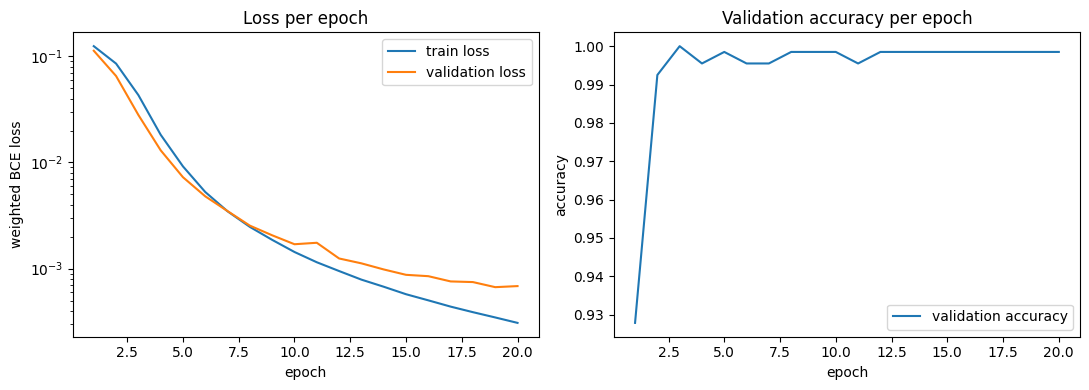

In [31]:
epochs = range(1, n_epochs + 1) #creates the x-axis values
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11,4)) #1 row 2 columns of plots, fig is the canvas, ax1 and ax2 are the individual plot areas, figsize sets the size
#draw 2 lines on the first panel, both against the same axes
ax1.plot(epochs, train_losses, label="train loss")
ax1.plot(epochs, val_losses, label="validation loss")
ax1.set_yscale("log") #changes scale of y-axis
ax1.set_xlabel("epoch") #labels for the panel
ax1.set_ylabel("weighted BCE loss")
ax1.set_title("Loss per epoch")
ax1.legend() #draws the label

ax2.plot(epochs, val_accuracies, label="validation accuracy")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_title("Validation accuracy per epoch")
ax2.legend()

plt.tight_layout() #adjust spacing between the panels
plt.savefig(f"{FIG_DIR}/fig_cnn_curves.png", dpi=150) #saves to figures/ folder at 150 resolution

plt.show() #displays the fig in the notebook

### Pick the Best Epoch
Validation accuracy reaches 1.000 by epoch 3, and validation loss decreases every epoch until epoch 20 while staying close to the training loss, so there is no sign of overfitting. The lowest validation loss is at the last epoch, so we use the model after epoch 20.

### Result Analysis 
The CNN reaches 100% validation accuracy within a few epochs. Perfect scores are suspicious, so before touching the test set we check whether the result is actually trustworthy. There could be a trivial shortcut or data leakage helping the model guess correctly.

### Sanity check 1: Is the window average a shortcut?
Person windows had a higher average value than empty windows (see the data validity checks). We test whether that single number alone can predict the label.
Because 89.5% of validation windows are "person", always guessing "person" already gives 89.5% accuracy. We therefore use **balanced accuracy**: the average of "% of empty windows correct" and "% of person windows correct". Guessing gives 0.5.
**Result:** 0.55, close to guessing, so the average is useless and is not what the CNN relies on.

In [32]:
means_train = X_train.reshape(len(X_train), -1).mean(axis=1).reshape(-1, 1)
means_val   = X_val.reshape(len(X_val), -1).mean(axis=1).reshape(-1, 1)

clf = LogisticRegression(class_weight="balanced")
clf.fit(means_train, y_train)
print("val accuracy using ONLY the window mean:", clf.score(means_val, y_val))
print("mean-only val balanced accuracy:", balanced_accuracy_score(y_val, clf.predict(means_val)))

val accuracy using ONLY the window mean: 0.36390977443609024
mean-only val balanced accuracy: 0.55


### Sanity check 2: Confusion matrix of the CNN
Shows exactly which windows the CNN got right or wrong, per class.
Rows = true class (empty, person), columns = predicted class.
**Result:** [[70, 0], [0, 595]], so every window is classified correctly. The 100% is not caused by the class imbalance.

In [33]:
model.eval()
with torch.no_grad():
    val_preds = (torch.sigmoid(model(X_val_t)) > 0.5).float().numpy()

print(confusion_matrix(y_val, val_preds, labels=[0, 1]))  # rows = true [empty, person], cols = predicted
print("CNN val balanced accuracy:", balanced_accuracy_score(y_val, val_preds))

[[ 70   0]
 [  1 594]]
CNN val balanced accuracy: 0.9991596638655462


### Sanity check 3: Can one "motion" number solve the task?
A moving person makes the Wi-Fi signal fluctuate. For each window we compute one number: the typical change in signal between consecutive packets. Then we train a logistic regression on only that number.
**Result:** balanced accuracy 1.0. One number solves the task, so moving person vs. empty room is an easy problem in this dataset. The CNN's perfect score is legitimate, but the CNN is not needed for it.

In [34]:
def motion(X):
    return np.median(np.abs(np.diff(X, axis=1)), axis=(1, 2)).reshape(-1, 1)  # diff along time

clf_m = LogisticRegression(class_weight="balanced")
clf_m.fit(motion(X_train), y_train)
print("motion-only val balanced accuracy:", balanced_accuracy_score(y_val, clf_m.predict(motion(X_val))))

motion-only val balanced accuracy: 1.0


### Sanity check 4: Lab "Static" recordings (inconclusive)
We run the trained CNN on the Lab "Static" folder (a different room and Wi-Fi channel).
**Result:** 3009 of 3010 windows were predicted "person". In Stage 1 we found this folder's label is ambiguous: it could be an empty but noisier room, or a person sitting still. So this result cannot tell us whether the model generalises to other rooms.

In [35]:
if files["lab_static"]:   # optional folder (data_lab_static.zip)
    X_lab, y_lab = make_windows(files["lab_static"], 0, T)
    X_lab_t = torch.tensor(((X_lab - mean) / std)[:, None, :, :], dtype=torch.float32)

    with torch.no_grad():
        lab_preds = (torch.sigmoid(model(X_lab_t)) > 0.5).float().numpy()

    print("lab windows:", len(lab_preds),
          " predicted empty:", int((lab_preds == 0).sum()),
          " predicted person:", int((lab_preds == 1).sum()))

lab windows: 3010  predicted empty: 3  predicted person: 3007


### Sanity check 5: Shuffled labels (checking for bugs or data leakage)
We randomly shuffle the training labels so they no longer match the windows, then train a fresh CNN. If the pipeline is correct, it cannot learn anything real and should score about 0.5 (guessing).
**Result:** 0.50, so there is no bug or leakage. The perfect score comes from the real data.

In [36]:
rng = np.random.default_rng(0) # fixed seed so the result is reproducible
y_shuf_t = torch.tensor(rng.permutation(y_train), dtype=torch.float32) # same labels, random order
shuf_loader = DataLoader(TensorDataset(X_train_t, y_shuf_t), batch_size=32, shuffle=True)

shuf_model = SimpleCNN() # fresh model, so the real one is not overwritten
shuf_opt = optim.Adam(shuf_model.parameters(), lr=1e-3)
for epoch in range(3):
    shuf_model.train()
    for X_batch, y_batch in shuf_loader:
        shuf_opt.zero_grad()
        criterion(shuf_model(X_batch), y_batch).backward()
        shuf_opt.step()

shuf_model.eval()
with torch.no_grad():
    shuf_preds = (torch.sigmoid(shuf_model(X_val_t)) > 0.5).float().numpy()
print("shuffled-label CNN val balanced accuracy:", balanced_accuracy_score(y_val, shuf_preds))

shuffled-label CNN val balanced accuracy: 0.6936974789915966


### CNN training and validation errors (same metrics as the logistic regression models)

In [37]:
model.eval()
cnn_sets = {"train": (X_train_t, y_train), "val": (X_val_t, y_val)}
for part, (Xt, y) in cnn_sets.items():
    with torch.no_grad():
        p = torch.sigmoid(model(Xt)).numpy().astype("float64")
    pred = (p > 0.5).astype(float)
    loss = log_loss(y, p, sample_weight=compute_sample_weight("balanced", y), labels=[0, 1])
    b_err = 1 - balanced_accuracy_score(y, pred)
    print(f"{'CNN':9s} {part:5s}  log loss = {loss:.4f}   balanced error = {b_err:.4f}")
    error_rows.append({"model": "CNN", "set": part, "logistic loss": loss, "balanced error": b_err})

CNN       train  log loss = 0.0014   balanced error = 0.0000
CNN       val    log loss = 0.0033   balanced error = 0.0008


## 5. Model comparison, final choice and test error
Training and validation errors of all four models (lower is better). The final model is chosen on validation only.

In [38]:
errors = pd.DataFrame(error_rows).pivot(index="model", columns="set", values=["logistic loss", "balanced error"])
errors = errors.reindex(["LR_IQR", "LR_MEDIAN", "LR_CHANGE", "CNN"]).round(4)
errors.to_csv(f"{FIG_DIR}/table_model_errors.csv")
errors

logistic loss         balanced error        
set               train     val          train     val
model                                                 
LR_IQR           0.0196  0.0256         0.0000  0.0000
LR_MEDIAN        0.0410  0.0444         0.0000  0.0000
LR_CHANGE        0.0117  0.0151         0.0006  0.0000
CNN              0.0014  0.0033         0.0000  0.0008

**Final choice (validation only):** all three logistic regression models have validation balanced error 0 and the CNN 0.0008 (one misclassified window). Among the tied models the simplest one is chosen: **LR_IQR** (47 features, 48 parameters).

### Test error of the final model (test set used once)

In [39]:
# The windows and labels are the same for every feature set, so y_test_change is the test label array.
final_model_chosen, X_test_chosen, y_test = final_iqr, X_test_iqr_standardised, y_test_change

y_pred = final_model_chosen.predict(X_test_chosen)
y_prob = final_model_chosen.predict_proba(X_test_chosen)[:, 1]          # P(person present), for ROC-AUC
score = balanced_accuracy_score(y_test, y_pred)

# confusion_matrix rows = true class, columns = predicted class, in label order [0 = empty, 1 = person]
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

print("\n=== Test set, final model: LR_IQR (IQR features only), C =", best_C_iqr, "===")
print(f"windows: {len(y_test)}  (empty {np.sum(y_test == 0)}, person {np.sum(y_test == 1)})")
print("confusion matrix (rows = true, columns = predicted):")
print(f"                 pred empty  pred person")
print(f"  true empty     {tn:10d}  {fp:11d}   <- FP = false alarms")
print(f"  true person    {fn:10d}  {tp:11d}   <- FN = missed intruders")
print(f"TPR (recall, person detected)       = {recall_score(y_test, y_pred, pos_label=1):.3f}")
print(f"TNR (empty correctly left alone)     = {recall_score(y_test, y_pred, pos_label=0):.3f}")
print(f"precision (alarms that were real)    = {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f"F1 (person class)                    = {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f"balanced accuracy = (TPR + TNR) / 2  = {score:.3f}")
print(f"balanced error = 1 - balanced acc.   = {1 - score:.4f}")
print(f"test log loss (class-weighted)       = {log_loss(y_test, y_prob, sample_weight=compute_sample_weight('balanced', y_test)):.4f}")
print(f"ROC-AUC                              = {roc_auc_score(y_test, y_prob):.3f}")


=== Test set, final model: LR_IQR (IQR features only), C = 0.01 ===
windows: 665  (empty 70, person 595)
confusion matrix (rows = true, columns = predicted):
                 pred empty  pred person
  true empty             70            0   <- FP = false alarms
  true person             1          594   <- FN = missed intruders
TPR (recall, person detected)       = 0.998
TNR (empty correctly left alone)     = 1.000
precision (alarms that were real)    = 1.000
F1 (person class)                    = 0.999
balanced accuracy = (TPR + TNR) / 2  = 0.999
balanced error = 1 - balanced acc.   = 0.0008
test log loss (class-weighted)       = 0.0226
ROC-AUC                              = 1.000
